# Step 3 — Speeding, tailgating, drifting and weaving

**Paper:** Romera, Bergasa, Arroyo, *"Need Data for Driver Behaviour Analysis? Presenting the Public UAH-DriveSet"*, IEEE ITSC 2016.

### Why this step?
In Step 2 we used the **motion sensor** to find hard brakes, accelerations and turns. That catches
**aggressive** drivers well, but **drowsy** drivers mostly don't brake hard. They **wander in their lane**.

The paper scores **7 behaviours**. Step 2 covered 3; this step covers the other 4, using the **GPS**
and the **camera**:

| Behaviour | Simple meaning | Data used | Our rule |
|---|---|---|---|
| 🏎️ **Speeding** | faster than the speed limit | GPS speed + speed limit from OpenStreetMap | **% of time more than 10% over the limit** |
| 🚗🚗 **Tailgating** | too close to the car in front | camera: distance to car ahead | **% of time less than 0.5 s behind the car ahead** |
| 〰️ **Drifting** | car not in the middle of its lane | lane camera | **% of time more than 0.5 m from the lane centre** |
| ↔️ **Weaving** | drifting away and then jerking back | lane camera | **times per minute: off by more than 0.6 m, then back within 0.2 m** |

We also count **lane changes per 10 km** (it turns out not to be useful; see section 5).

### How we chose each rule
Same idea as Step 2: we try a few sensible values, and keep the one whose result **agrees best with
the app's own score** for that behaviour (from `SEMANTIC_FINAL.txt`). Agreement is measured with
**correlation**: −1 or +1 = perfect agreement, 0 = no relation.
The app's scores are "out of 100, higher = safer", so when **our** number goes up (more speeding)
the app's score goes **down**. That means a good match shows as a correlation close to **−1**.

All the code is in `behaviour_features.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from uah_driveset import list_trips, load_trip, load_summaries
import behaviour_features as bf

plt.rcParams["figure.figsize"] = (12, 4)
COLORS = {"NORMAL": "tab:green", "AGGRESSIVE": "tab:red", "DROWSY": "tab:blue"}
ORDER = ["NORMAL", "DROWSY", "AGGRESSIVE"]

trips = list_trips()
summary = load_summaries(trips)          # the app's own scores per trip
trip_data = {row.trip_id: load_trip(row) for _, row in trips.iterrows()}
print(len(trip_data), "trips loaded")

def pick(driver, behavior, road, n=0):
    row = trips[(trips.driver == driver) & (trips.behavior == behavior) & (trips.road == road)].iloc[n]
    return trip_data[row.trip_id]

def compare_rules(rules, app_col):
    """For each candidate rule: average per driving style + agreement with the app's score."""
    rows = []
    for name, fn in rules.items():
        values = pd.Series([fn(trip_data[t]) for t in trips.trip_id])
        rec = {"rule": name}
        rec.update(values.groupby(trips.behavior).mean().reindex(ORDER).round(2).to_dict())
        rec["agreement with app (corr)"] = round(values.corr(summary[app_col]), 2)
        rows.append(rec)
    return pd.DataFrame(rows).set_index("rule")

40 trips loaded


## 1. Speeding 🏎️

**Data:** the GPS gives our speed every second. OpenStreetMap (a free online map) tells us the
speed limit of the road we are on.

**Rule:** the car is speeding when its speed is **more than 10% over the limit**
(e.g. above 110 km/h on a 100 km/h road). The trip's number is the **% of time spent speeding**.

### Example: same driver, same road, normal vs aggressive
The red shading marks the moments the driver was more than 10% over the limit.

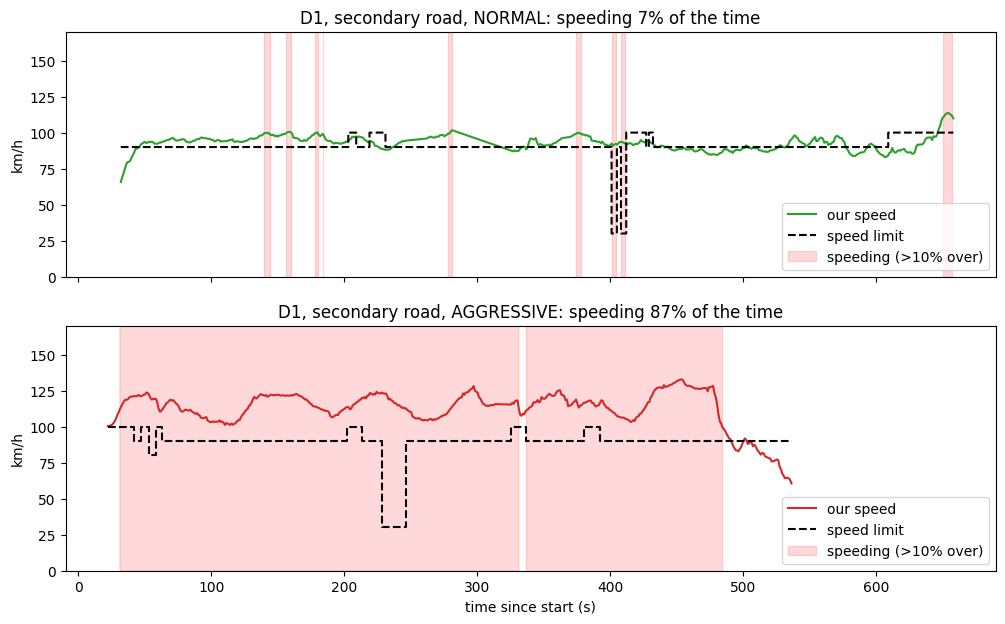

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, behavior in zip(axes, ["NORMAL", "AGGRESSIVE"]):
    trip = pick("D1", behavior, "SECONDARY", n=1 if behavior == "NORMAL" else 0)
    s = bf.speed_vs_limit(trip["gps"], trip["osm"])
    too_fast = s.speed_kmh > 1.1 * s.speed_limit_kmh
    ax.plot(s.time, s.speed_kmh, color=COLORS[behavior], label="our speed")
    ax.step(s.time, s.speed_limit_kmh, where="post", color="black", ls="--", label="speed limit")
    ax.fill_between(s.time, 0, 200, where=too_fast, color="red", alpha=0.15, step="post", label="speeding (>10% over)")
    ax.set_ylim(0, 170)
    ax.set_ylabel("km/h")
    ax.set_title(f"D1, secondary road, {behavior}: speeding {too_fast.mean() * 100:.0f}% of the time")
    ax.legend(loc="lower right")
axes[-1].set_xlabel("time since start (s)")
plt.show()

### Choosing the rule
We tried three versions of "speeding". **10% over the limit** agrees best with the app.
"Any amount over" counts tiny overshoots of 1–2 km/h, which everyone does.

⚠️ **Note:** the speed limits come from OpenStreetMap and are sometimes wrong. In the chart above the
limit suddenly drops to 30 km/h for a few seconds on a 90 km/h road, which is probably a map error. The
10% margin, and counting % of the whole trip, keep such short errors from mattering much.

In [3]:
compare_rules({
    "any amount over the limit": lambda t: bf.speeding_pct(t["gps"], t["osm"], margin=0.0),
    "more than 10% over (chosen)": lambda t: bf.speeding_pct(t["gps"], t["osm"], margin=0.10),
    "more than 20% over": lambda t: bf.speeding_pct(t["gps"], t["osm"], margin=0.20),
}, "score_overspeed")

,NORMAL,DROWSY,AGGRESSIVE,agreement with app (corr)
rule,,,,
any amount over the limit,26.32,21.45,51.78,-0.69
more than 10% over (chosen),5.20,5.50,29.68,-0.86
more than 20% over,2.33,1.19,13.48,-0.84


## 2. Tailgating 🚗🚗

**Data:** the camera measures the **distance to the car in front** (in metres).

But "20 m behind" is fine in a traffic jam and dangerous on a motorway. So, like driving instructors,
we use **time**, not distance:

> **time gap = distance to the car ahead ÷ our speed**

Example: 25 m behind at 90 km/h (= 25 m/s) → 25 ÷ 25 = **1 second** gap.

Driving schools teach the **"2-second rule"**. Below **0.5 s** you have almost no time to react if
the car ahead brakes.

**Rule:** the trip's number is the **% of time with a gap of less than 0.5 s** to the car ahead.

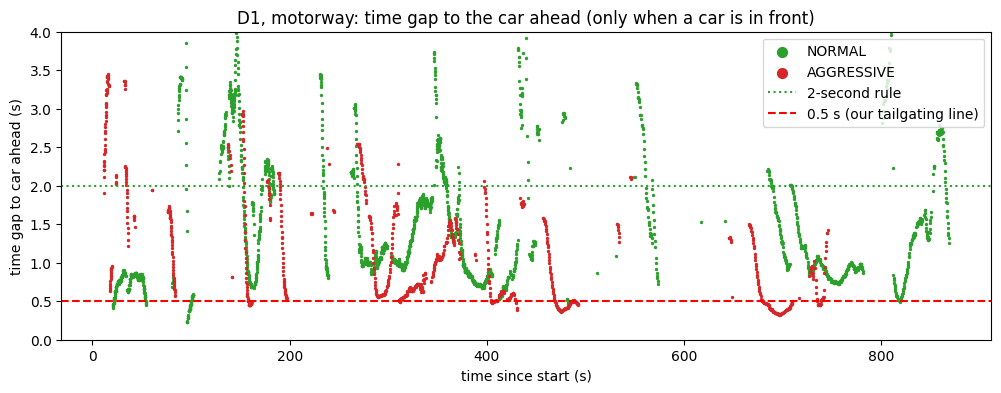

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
for behavior in ["NORMAL", "AGGRESSIVE"]:
    v = bf.time_gap_to_car_ahead(pick("D1", behavior, "MOTORWAY")["vehicles"])
    ax.scatter(v.time, v.gap_s, s=2, color=COLORS[behavior], label=behavior)
ax.axhline(2.0, color="tab:green", ls=":", label="2-second rule")
ax.axhline(0.5, color="red", ls="--", label="0.5 s (our tailgating line)")
ax.set_ylim(0, 4)
ax.set_xlabel("time since start (s)")
ax.set_ylabel("time gap to car ahead (s)")
ax.set_title("D1, motorway: time gap to the car ahead (only when a car is in front)")
ax.legend(markerscale=5, loc="upper right")
plt.show()

### Choosing the rule
We tried the 2-second rule, 1 second and 0.5 seconds. **0.5 s** agrees almost perfectly with the app
(correlation close to −1). With 2 s, even normal drivers in busy traffic get counted.

In [5]:
compare_rules({
    "gap < 2 s": lambda t: bf.tailgating_pct(t["vehicles"], gap_s=2.0),
    "gap < 1 s": lambda t: bf.tailgating_pct(t["vehicles"], gap_s=1.0),
    "gap < 0.5 s (chosen)": lambda t: bf.tailgating_pct(t["vehicles"], gap_s=0.5),
}, "score_carfollow")

,NORMAL,DROWSY,AGGRESSIVE,agreement with app (corr)
rule,,,,
gap < 2 s,32.47,25.21,57.45,-0.64
gap < 1 s,16.81,11.04,48.70,-0.79
gap < 0.5 s (chosen),1.16,0.63,21.21,-0.97


## 3. Drifting 〰️

**Data:** the lane camera measures how far the **centre of the car** is from the **centre of the
lane** (in metres). A lane is about 3 m wide and a car about 1.8 m, so there is only about 0.6 m of
space on each side.

We only use moments when the camera could clearly see the lane lines (`lane_state = 2`).

**Rule:** the trip's number is the **% of time the car is more than 0.5 m from the lane centre**.

### Example: same driver, same road, normal vs drowsy

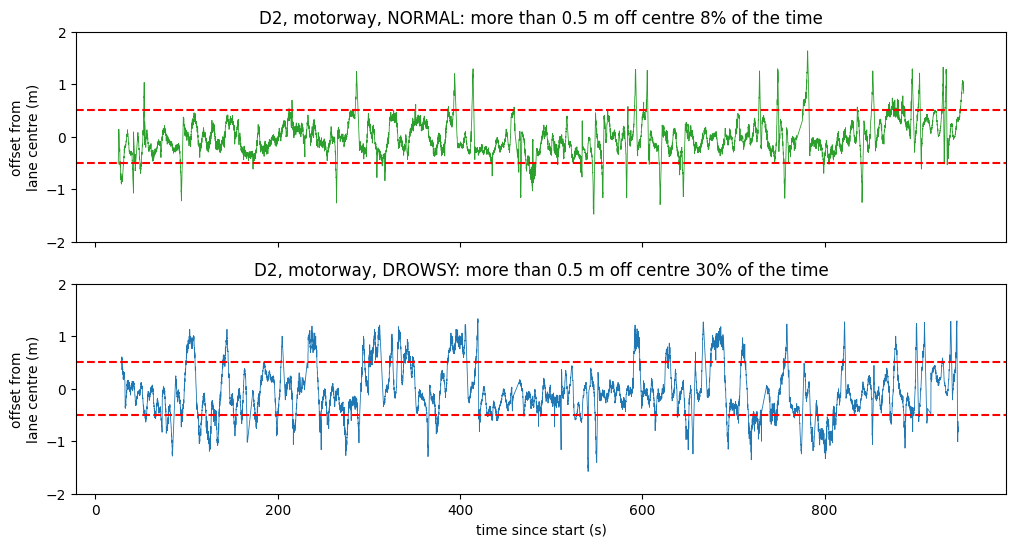

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, behavior in zip(axes, ["NORMAL", "DROWSY"]):
    l = bf.tracked_lane(pick("D2", behavior, "MOTORWAY")["lanes"])
    pct = (l.lane_offset_m.abs() > 0.5).mean() * 100
    ax.plot(l.time, l.lane_offset_m, color=COLORS[behavior], lw=0.6)
    ax.axhline(0.5, color="red", ls="--")
    ax.axhline(-0.5, color="red", ls="--")
    ax.set_ylim(-2, 2)
    ax.set_ylabel("offset from\nlane centre (m)")
    ax.set_title(f"D2, motorway, {behavior}: more than 0.5 m off centre {pct:.0f}% of the time")
axes[-1].set_xlabel("time since start (s)")
plt.show()

The big jumps are **lane changes**: the camera switches to measuring the new lane. Drowsy driving
spends much more time outside the red lines.

### Choosing the rule

In [7]:
compare_rules({
    "more than 0.3 m off centre": lambda t: bf.drifting_pct(t["lanes"], drift_m=0.3),
    "more than 0.5 m off centre (chosen)": lambda t: bf.drifting_pct(t["lanes"], drift_m=0.5),
    "more than 0.7 m off centre": lambda t: bf.drifting_pct(t["lanes"], drift_m=0.7),
}, "score_drifting")

,NORMAL,DROWSY,AGGRESSIVE,agreement with app (corr)
rule,,,,
more than 0.3 m off centre,32.27,61.71,36.78,-0.87
more than 0.5 m off centre (chosen),8.46,37.69,13.24,-0.88
more than 0.7 m off centre,2.66,17.28,4.15,-0.80


## 4. Weaving ↔️

At first we thought "weaving" meant **changing lanes a lot**. But the app gives its **worst weaving
scores to drowsy drivers**, not aggressive ones. So the app's "weaving" means **zig-zagging inside the
lane**: a sleepy driver slowly drifts towards the edge, notices, and **jerks the wheel back**.

**Rule:** count every time the car
1. drifts **more than 0.6 m** from the lane centre, and then
2. comes back to **within 0.2 m** of the centre (the correction).

The trip's number is **corrections per minute**.

### Example: a drowsy trip, zoomed in
Each ✕ is one counted "drift and correct".

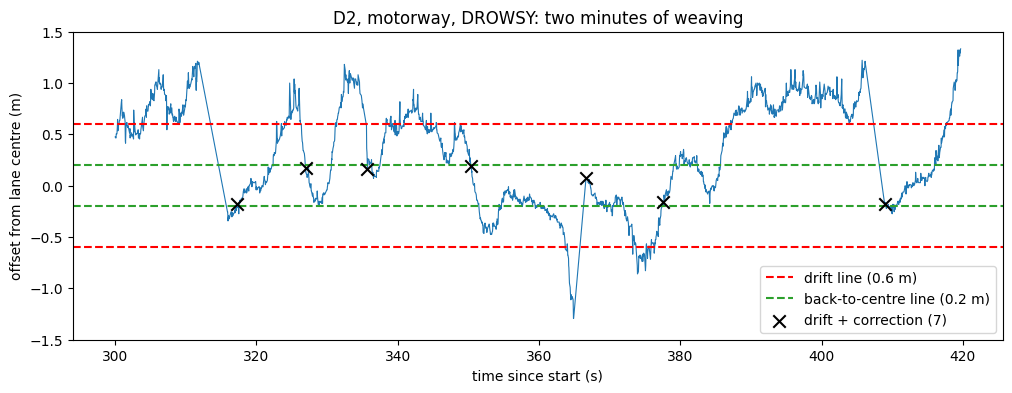

In [8]:
l = bf.tracked_lane(pick("D2", "DROWSY", "MOTORWAY")["lanes"])
l = l[(l.time > 300) & (l.time < 420)]
marks, drifted = [], False
for t_, off in zip(l.time, l.lane_offset_m):
    if abs(off) > 0.6:
        drifted = True
    elif drifted and abs(off) < 0.2:
        marks.append((t_, off))
        drifted = False

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(l.time, l.lane_offset_m, color=COLORS["DROWSY"], lw=0.8)
for y, c, lab in [(0.6, "red", "drift line (0.6 m)"), (0.2, "tab:green", "back-to-centre line (0.2 m)")]:
    ax.axhline(y, color=c, ls="--", label=lab)
    ax.axhline(-y, color=c, ls="--")
if marks:
    ax.scatter(*zip(*marks), marker="x", color="black", s=80, zorder=3, label=f"drift + correction ({len(marks)})")
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel("time since start (s)")
ax.set_ylabel("offset from lane centre (m)")
ax.set_title("D2, motorway, DROWSY: two minutes of weaving")
ax.legend(loc="lower right")
plt.show()

### Choosing the rule

In [9]:
compare_rules({
    "off > 0.4 m, back < 0.2 m": lambda t: bf.weaving_per_min(t["lanes"], out_m=0.4, back_m=0.2),
    "off > 0.5 m, back < 0.2 m": lambda t: bf.weaving_per_min(t["lanes"], out_m=0.5, back_m=0.2),
    "off > 0.6 m, back < 0.2 m (chosen)": lambda t: bf.weaving_per_min(t["lanes"], out_m=0.6, back_m=0.2),
    "off > 0.8 m, back < 0.2 m": lambda t: bf.weaving_per_min(t["lanes"], out_m=0.8, back_m=0.2),
}, "score_weaving")

,NORMAL,DROWSY,AGGRESSIVE,agreement with app (corr)
rule,,,,
"off > 0.4 m, back < 0.2 m",3.29,5.07,4.51,-0.46
"off > 0.5 m, back < 0.2 m",2.15,4.44,3.25,-0.64
"off > 0.6 m, back < 0.2 m (chosen)",1.54,3.86,2.43,-0.69
"off > 0.8 m, back < 0.2 m",1.00,2.65,1.52,-0.66


Weaving agrees less with the app than the others (correlation about −0.7). The app probably uses
a more detailed method that the paper does not fully describe, but our simple rule clearly points
at drowsy drivers.

## 5. Lane changes

The dataset also lists every lane change. Does changing lanes often mean bad driving?

In [10]:
lc = pd.DataFrame({
    "behavior": trips.behavior,
    "lane_changes_per10km": [bf.lane_changes_per_10km(trip_data[r.trip_id]["lane_changes"], r.distance_km)
                             for _, r in trips.iterrows()],
})
table = lc.groupby("behavior").lane_changes_per10km.mean().reindex(ORDER).round(2).to_frame().T
table["agreement with app weaving score (corr)"] = round(lc.lane_changes_per10km.corr(summary.score_weaving), 2)
table

behavior,NORMAL,DROWSY,AGGRESSIVE,agreement with app weaving score (corr)
lane_changes_per10km,4.26,5.55,5.22,-0.16


Not really: all three driving styles change lanes about equally often (4–6 times per 10 km), and the
number has almost no relation to the app's weaving score. Changing lanes is a **normal** part of
driving, especially on the motorway. So we keep it as information only and do not use it as a risk sign.

## 6. All features together, for every trip

In [11]:
features = pd.DataFrame([
    {"trip_id": row.trip_id, "driver": row.driver, "behavior": row.behavior, "road": row.road,
     "distance_km": row.distance_km,
     **bf.trip_behaviour_features(trip_data[row.trip_id], row.distance_km)}
    for _, row in trips.iterrows()
])
main = ["speeding_pct", "tailgating_pct", "drifting_pct", "weaving_per_min", "lane_changes_per10km"]
features.groupby("behavior")[main].mean().reindex(ORDER).round(2)

,speeding_pct,tailgating_pct,drifting_pct,weaving_per_min,lane_changes_per10km
behavior,,,,,
NORMAL,5.20,1.16,8.46,1.54,4.26
DROWSY,5.50,0.63,37.69,3.86,5.55
AGGRESSIVE,29.68,21.21,13.24,2.43,5.22


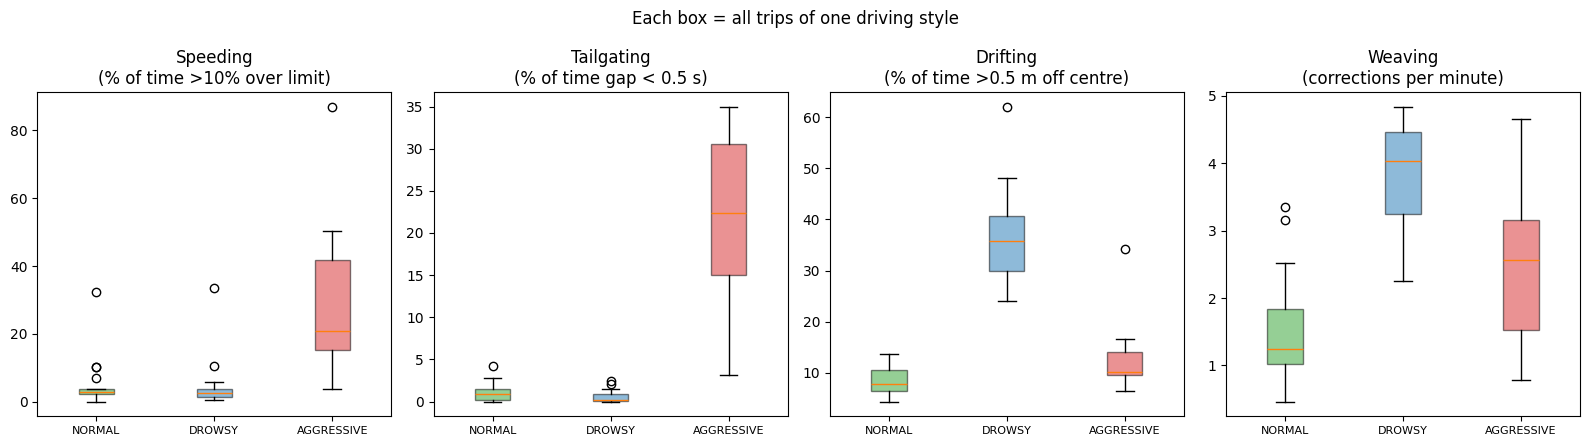

In [12]:
titles = {"speeding_pct": "Speeding\n(% of time >10% over limit)",
          "tailgating_pct": "Tailgating\n(% of time gap < 0.5 s)",
          "drifting_pct": "Drifting\n(% of time >0.5 m off centre)",
          "weaving_per_min": "Weaving\n(corrections per minute)"}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (col, title) in zip(axes, titles.items()):
    data = [features.loc[features.behavior == b, col] for b in ORDER]
    box = ax.boxplot(data, tick_labels=ORDER, patch_artist=True)
    for patch, b in zip(box["boxes"], ORDER):
        patch.set_facecolor(COLORS[b])
        patch.set_alpha(0.5)
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Each box = all trips of one driving style")
plt.tight_layout()
plt.show()

**Reading the boxes:**
- **Speeding** and **tailgating** are much higher for **aggressive** drivers (red).
- **Drifting** and **weaving** are much higher for **drowsy** drivers (blue).
- **Normal** drivers (green) are low on all four.

So Step 2 + Step 3 together give us signals for **both** kinds of risky driving.

## 7. How well do we agree with the app?

Each dot is one trip. On the x-axis is our number, on the y-axis the app's score for the same
behaviour (out of 100, higher = safer). A clear downward line means strong agreement.

To check that this isn't luck, we also compute the agreement on drivers **D4–D6 only**.

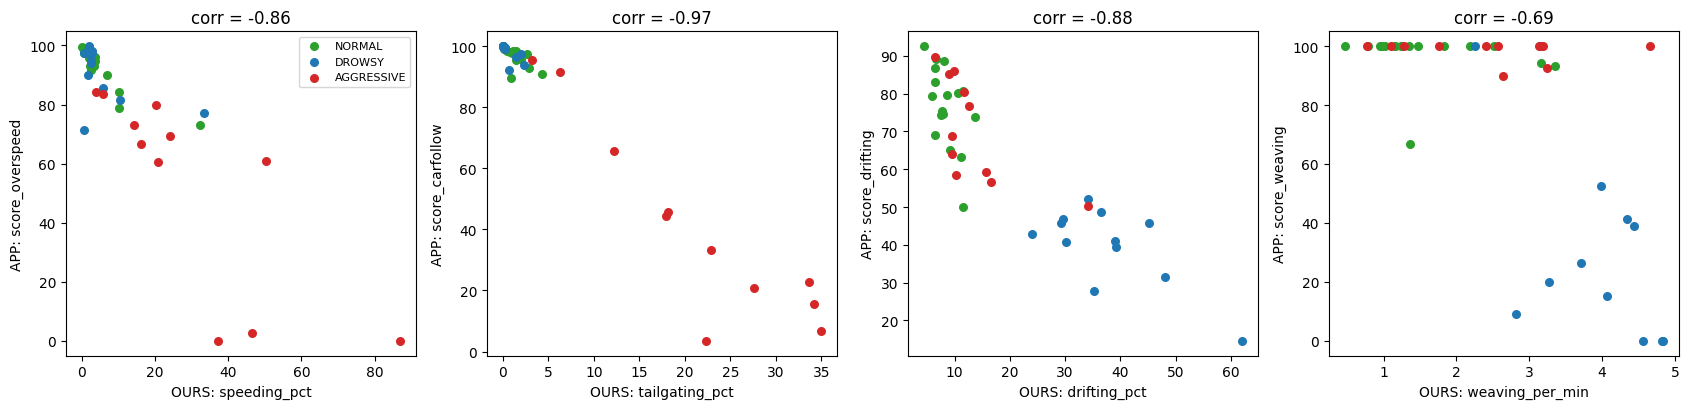

,app score,corr (all 40 trips),corr (D4-D6 only)
our feature,,,
speeding_pct,score_overspeed,-0.86,-0.90
tailgating_pct,score_carfollow,-0.97,-0.96
drifting_pct,score_drifting,-0.88,-0.97
weaving_per_min,score_weaving,-0.69,-0.74


In [13]:
pairs = [("speeding_pct", "score_overspeed"), ("tailgating_pct", "score_carfollow"),
         ("drifting_pct", "score_drifting"), ("weaving_per_min", "score_weaving")]
test = trips.driver.isin(["D4", "D5", "D6"])
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
rows = []
for ax, (ours, app) in zip(axes, pairs):
    for b in ORDER:
        m = features.behavior == b
        ax.scatter(features.loc[m, ours], summary.loc[m, app], color=COLORS[b], label=b, s=30)
    r_all = features[ours].corr(summary[app])
    r_test = features.loc[test, ours].corr(summary.loc[test, app])
    rows.append({"our feature": ours, "app score": app, "corr (all 40 trips)": round(r_all, 2),
                 "corr (D4-D6 only)": round(r_test, 2)})
    ax.set_xlabel(f"OURS: {ours}")
    ax.set_ylabel(f"APP: {app}")
    ax.set_title(f"corr = {r_all:.2f}")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("our feature")

## 8. Save all features (Step 2 + Step 3) for the next steps

We join the harsh-event rates from Step 2 with today's four behaviours: one row per trip,
one column per risk signal. This table is the **input for the classifier and the safety score**.

In [14]:
from pathlib import Path
step2 = pd.read_csv("../results/step2_trip_events.csv")
all_features = step2.merge(features[["trip_id"] + main], on="trip_id")
Path("../results").mkdir(exist_ok=True)
all_features.to_csv("../results/step3_trip_features.csv", index=False)
print(all_features.shape[0], "trips,", all_features.shape[1], "columns")
all_features[["trip_id", "behavior", "braking_per10km", "acceleration_per10km", "turning_per10km"] + main[:4]].head()

40 trips, 18 columns


,trip_id,behavior,braking_per10km,acceleration_per10km,turning_per10km,speeding_pct,tailgating_pct,drifting_pct,weaving_per_min
0,20151110175712-16km-D1-NORMAL1-SECONDARY,NORMAL,0.000000,0.0,2.500000,32.209738,1.477105,11.176866,1.352788
1,20151110180824-16km-D1-NORMAL2-SECONDARY,NORMAL,2.500000,0.0,1.250000,6.878307,2.643737,11.524717,1.249680
2,20151111123124-25km-D1-NORMAL-MOTORWAY,NORMAL,1.200000,0.0,0.800000,3.009259,1.130681,8.703671,3.357152
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,AGGRESSIVE,2.916667,0.0,3.333333,50.339213,6.262425,9.033376,4.654138
4,20151111132348-25km-D1-DROWSY-MOTORWAY,DROWSY,2.800000,0.0,2.000000,2.909483,2.048000,24.001922,3.715488


## Summary

| Behaviour | Our rule | Highest for | Agreement with app |
|---|---|---|---|
| Speeding | % of time >10% over the limit | 🔴 Aggressive (≈30% vs ≈5%) | strong (≈ −0.86) |
| Tailgating | % of time <0.5 s behind the car ahead | 🔴 Aggressive (≈21% vs ≈1%) | very strong (≈ −0.97) |
| Drifting | % of time >0.5 m off lane centre | 🔵 Drowsy (≈38% vs ≈8%) | strong (≈ −0.88) |
| Weaving | drift >0.6 m then back <0.2 m, per minute | 🔵 Drowsy (≈3.9 vs ≈1.5) | moderate (≈ −0.69) |
| Lane changes | per 10 km | nobody in particular | not useful |

**Main finding:** the motion sensor (Step 2) plus speeding and tailgating catch **aggressive** driving;
the lane camera (drifting and weaving) catches **drowsy** driving.

**Next step (Step 4):** turn these numbers into **scores out of 100** for each behaviour, like the app
does, and combine them into one overall score per trip.